# Trene modellen




In [2]:
from pathlib import Path

import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [3]:
df = pd.read_csv("data/timetabell.csv", index_col="tid")
df.index = pd.to_datetime(df.index, utc=True)

# Kalenderfeaturane skal vere i norsk tid: rushet er kl. 08 her, ikkje kl. 06 UTC
df["tid_lokal"] = df.index.tz_convert("Europe/Oslo")
print(df.head())
print(len(df), "timar")

                           turar  temp  vind  nedbor                 tid_lokal
tid                                                                           
2018-06-29 10:00:00+00:00      2  19.9   5.5     0.0 2018-06-29 12:00:00+02:00
2018-06-29 11:00:00+00:00      6  21.0   6.4     0.0 2018-06-29 13:00:00+02:00
2018-06-29 12:00:00+00:00     20  22.4   6.4     0.0 2018-06-29 14:00:00+02:00
2018-06-29 13:00:00+00:00     37  22.4   6.4     0.0 2018-06-29 15:00:00+02:00
2018-06-29 14:00:00+00:00     40  22.0   7.3     0.0 2018-06-29 16:00:00+02:00
56821 timar


For å få same features i trening/utforsking og i appen lagar eg dei i eit eige pythonprogram som eg kan nytta her og der. 

In [4]:
from features import lag_features

In [5]:
X = lag_features(df)
y = df["turar"]
print(X.head())
print("Heilagdagstimar:", X["heilagdag"].sum())

                           time  vekedag  maned  heilagdag  temp  nedbor
tid                                                                     
2018-06-29 10:00:00+00:00    12        4      6          0  19.9     0.0
2018-06-29 11:00:00+00:00    13        4      6          0  21.0     0.0
2018-06-29 12:00:00+00:00    14        4      6          0  22.4     0.0
2018-06-29 13:00:00+00:00    15        4      6          0  22.4     0.0
2018-06-29 14:00:00+00:00    16        4      6          0  22.0     0.0
Heilagdagstimar: 1805


## Tidsdeling og baseline

In [6]:
ar = df["tid_lokal"].dt.year

X_tr, y_tr = X[ar == 2023], y[ar == 2023]   # trening
X_va, y_va = X[ar == 2024], y[ar == 2024]   # validering
X_te, y_te = X[ar == 2025], y[ar == 2025]   # test

print("Trening:", len(X_tr), " Validering:", len(X_va), " Test:", len(X_te))

Trening: 6935  Validering: 6921  Test: 6532


In [7]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

def mal(sann, pred):
    """Rekn ut metrikkane for eitt sett prediksjonar."""
    return {
        "MAE": mean_absolute_error(sann, pred),
        "RMSE": root_mean_squared_error(sann, pred),
        "skeivheit": np.mean(pred - sann),   # under 0: spår for lågt
    }

# Baseline: snittet for same time, vekedag og månad i treningsdata
nokkel = ["time", "vekedag", "maned"]
snitt = y_tr.groupby([X_tr[k] for k in nokkel]).mean().rename("pred")

def pred_baseline(X_ny):
    # Slå opp snittet for kvar rad. Kombinasjonar vi ikkje har sett, får totalsnittet.
    return X_ny[nokkel].join(snitt, on=nokkel)["pred"].fillna(y_tr.mean()).values

print("Baseline trening:  ", mal(y_tr, pred_baseline(X_tr)))
print("Baseline validering:", mal(y_va, pred_baseline(X_va)))

Baseline trening:   {'MAE': 16.073727469358325, 'RMSE': 24.45260103114137, 'skeivheit': np.float64(1.6393199383073688e-16)}
Baseline validering: {'MAE': 20.558300823580407, 'RMSE': 30.148329041053582, 'skeivheit': np.float64(9.541670278861437)}


In [8]:
print(y.groupby(ar).mean().round(1))

tid_lokal
2018     29.5
2019    135.3
2020    153.5
2021     94.7
2022     77.1
2023     67.4
2024     57.6
2025     44.1
2026     35.5
Name: turar, dtype: float64


In [9]:
for start in [2021, 2023]:
    maske = (ar >= start) & (ar <= 2023)
    snitt = y[maske].groupby([X[maske][k] for k in nokkel]).mean().rename("pred")
    pred = X_va[nokkel].join(snitt, on=nokkel)["pred"].fillna(y[maske].mean()).values
    print(f"Trening {start}–2023:", mal(y_va, pred))

Trening 2021–2023: {'MAE': 25.39864348193347, 'RMSE': 36.1453703177712, 'skeivheit': np.float64(21.577934835477095)}
Trening 2023–2023: {'MAE': 20.558300823580407, 'RMSE': 30.148329041053582, 'skeivheit': np.float64(9.541670278861437)}


## Ridge

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

KATEGORISKE = ["time", "vekedag", "maned", "heilagdag"]
NUMERISKE = ["temp", "nedbor"]

# Kategoriar blir ja/nei-kolonnar, tala blir standardiserte
forbehandling = ColumnTransformer([
    ("kat", OneHotEncoder(handle_unknown="ignore"), KATEGORISKE),
    ("tal", StandardScaler(), NUMERISKE),
])

for alpha in [0.1, 1, 10, 100]:
    ridge = Pipeline([("forb", forbehandling), ("ridge", Ridge(alpha=alpha))])
    ridge.fit(X_tr, y_tr)
    print(f"alpha={alpha}:", mal(y_va, ridge.predict(X_va)))

alpha=0.1: {'MAE': 25.34793682291104, 'RMSE': 32.96332238553156, 'skeivheit': np.float64(11.446010852567099)}
alpha=1: {'MAE': 25.345895299445875, 'RMSE': 32.95495290322875, 'skeivheit': np.float64(11.449068981623459)}
alpha=10: {'MAE': 25.333219756224413, 'RMSE': 32.88575413492513, 'skeivheit': np.float64(11.476776075713033)}
alpha=100: {'MAE': 25.81038144508416, 'RMSE': 33.12368412904319, 'skeivheit': np.float64(11.600157194685806)}


In [11]:
def med_samspel(X_):
    X_ = X_.copy()
    helg = (X_["vekedag"] >= 5).map({True: "helg", False: "kvardag"})
    X_["time_dagtype"] = X_["time"].astype(str) + "_" + helg
    return X_

forbehandling2 = ColumnTransformer([
    ("kat", OneHotEncoder(handle_unknown="ignore"), KATEGORISKE + ["time_dagtype"]),
    ("tal", StandardScaler(), NUMERISKE),
])
ridge2 = Pipeline([("forb", forbehandling2), ("ridge", Ridge(alpha=10))])
ridge2.fit(med_samspel(X_tr), y_tr)
print("Ridge med samspel:", mal(y_va, ridge2.predict(med_samspel(X_va))))

Ridge med samspel: {'MAE': 21.112004404454396, 'RMSE': 27.840659531742833, 'skeivheit': np.float64(11.388629893488226)}


## Trebaserte modellar

In [12]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

# Tre deler på terskelverdiar, så dei treng korkje one-hot eller skalering
forest = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=42)
hgb = HistGradientBoostingRegressor(loss="poisson", early_stopping=False, random_state=42)

forest.fit(X_tr, y_tr)
hgb.fit(X_tr, y_tr)

for namn, modell in [("Random forest", forest), ("Gradient boosting", hgb)]:
    print(namn, "trening:   ", mal(y_tr, modell.predict(X_tr)))
    print(namn, "validering:", mal(y_va, modell.predict(X_va)))

Random forest trening:    {'MAE': 10.125787401675277, 'RMSE': 15.207822570433999, 'skeivheit': np.float64(0.15592991544499313)}
Random forest validering: {'MAE': 16.689159084775618, 'RMSE': 24.070101498959083, 'skeivheit': np.float64(10.686449642042364)}
Gradient boosting trening:    {'MAE': 9.952771193638002, 'RMSE': 14.689526179998657, 'skeivheit': np.float64(0.003065395410425167)}
Gradient boosting validering: {'MAE': 15.200650354106823, 'RMSE': 21.51321405695995, 'skeivheit': np.float64(9.403490065396442)}


## Test på 2025

In [13]:
from sklearn.base import clone

# Same oppsett som vinnaren, men trena på 2024
endeleg = clone(hgb)
endeleg.fit(X_va, y_va)

pred_te = endeleg.predict(X_te)
print("Gradient boosting, test 2025:", mal(y_te, pred_te))

# Baselinen på same måte, til samanlikning
snitt24 = y_va.groupby([X_va[k] for k in nokkel]).mean().rename("pred")
pred_base_te = X_te[nokkel].join(snitt24, on=nokkel)["pred"].fillna(y_va.mean()).values
print("Baseline, test 2025:         ", mal(y_te, pred_base_te))

Gradient boosting, test 2025: {'MAE': 16.078614280312348, 'RMSE': 23.58026658425125, 'skeivheit': np.float64(14.088687050356627)}
Baseline, test 2025:          {'MAE': 19.14622116758522, 'RMSE': 29.44396551186607, 'skeivheit': np.float64(14.50835629720351)}


## Figurar og feilanalyse

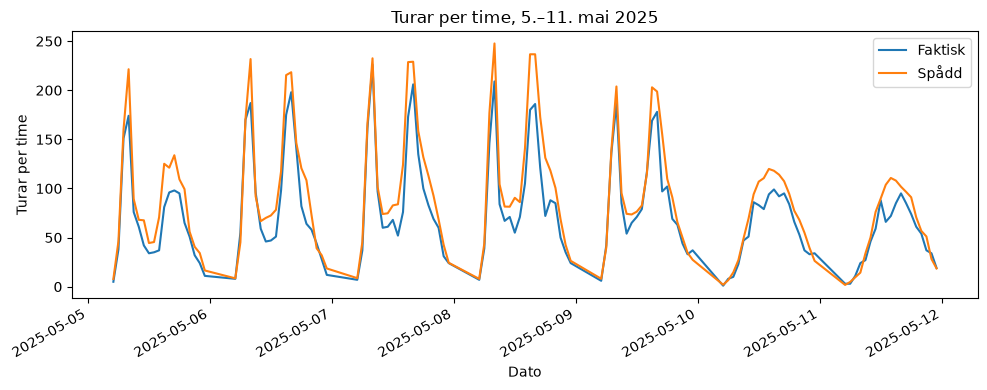

In [14]:
import joblib

Path("figurar").mkdir(exist_ok=True)
joblib.dump(endeleg, "modell.joblib")

# Figur: ei veke i mai 2025, spådd mot faktisk
lokal_te = df.loc[X_te.index, "tid_lokal"]
veke = (lokal_te >= "2025-05-05") & (lokal_te < "2025-05-12")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(lokal_te[veke], y_te[veke], label="Faktisk")
ax.plot(lokal_te[veke], pred_te[veke], label="Spådd")
ax.set(title="Turar per time, 5.–11. mai 2025", xlabel="Dato", ylabel="Turar per time")
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig("figurar/veke_test.png", dpi=150)
plt.show()

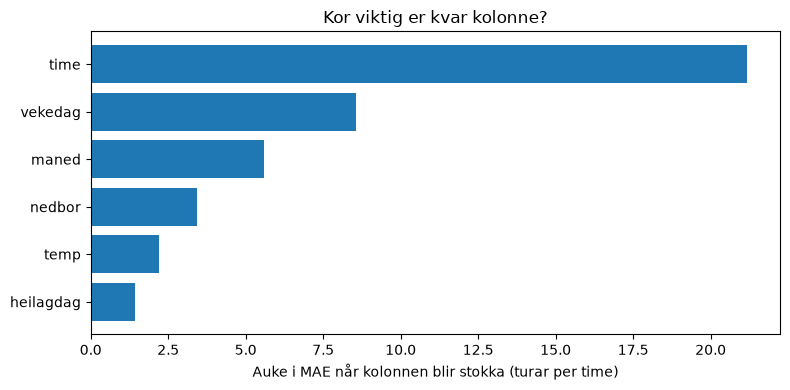

In [15]:
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

# Stokk éin kolonne om gongen og sjå kor mykje feilen aukar
vikt = permutation_importance(endeleg, X_te, y_te, n_repeats=5, random_state=42,
                              scoring="neg_mean_absolute_error")
rekkje = vikt.importances_mean.argsort()

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(X_te.columns[rekkje], vikt.importances_mean[rekkje])
ax.set(title="Kor viktig er kvar kolonne?",
       xlabel="Auke i MAE når kolonnen blir stokka (turar per time)")
fig.tight_layout()
fig.savefig("figurar/viktigheit.png", dpi=150)
plt.show()

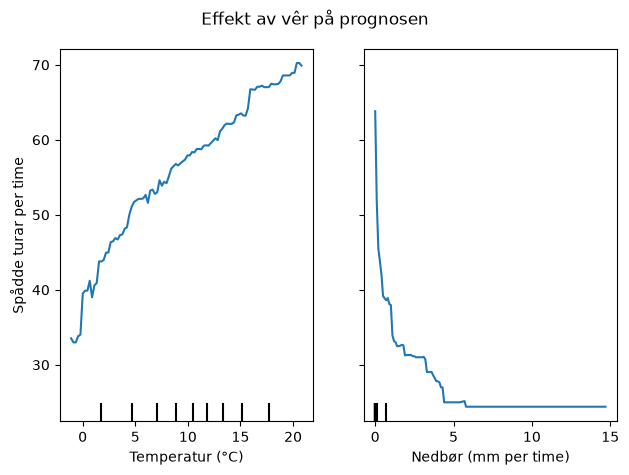

In [16]:
disp = PartialDependenceDisplay.from_estimator(endeleg, X_te, ["temp", "nedbor"], method="brute")
disp.axes_[0, 0].set(xlabel="Temperatur (°C)", ylabel="Spådde turar per time")
disp.axes_[0, 1].set(xlabel="Nedbør (mm per time)")
disp.figure_.suptitle("Effekt av vêr på prognosen")
disp.figure_.tight_layout()
disp.figure_.savefig("figurar/ver_effekt.png", dpi=150)
plt.show()

Sjekk på valideringsdata: betyr vind noko? (grunnlaget for å fjerne vind)

In [17]:
vikt_va = permutation_importance(hgb, X_va, y_va, n_repeats=5, random_state=42,
                                 scoring="neg_mean_absolute_error")
print(pd.Series(vikt_va.importances_mean, index=X_va.columns).sort_values().round(2))

heilagdag     1.50
temp          4.70
maned         5.60
nedbor        5.92
vekedag      11.12
time         28.67
dtype: float64


## Resultattabell

In [18]:
Path("resultat").mkdir(exist_ok=True)

ridge = Pipeline([("forb", forbehandling), ("ridge", Ridge(alpha=10))]).fit(X_tr, y_tr)

modellar = {
    "Baseline": pred_baseline,
    "Ridge": ridge.predict,
    "Ridge med samspel": lambda X_: ridge2.predict(med_samspel(X_)),
    "Random forest": forest.predict,
    "Gradient boosting": hgb.predict,
}

rader = []
for namn, pred in modellar.items():
    for data, (X_d, y_d) in {"trening 2023": (X_tr, y_tr), "validering 2024": (X_va, y_va)}.items():
        rader.append({"modell": namn, "data": data} | mal(y_d, pred(X_d)))

# Testen: trena på 2024, spådd på 2025
rader.append({"modell": "Baseline", "data": "test 2025"} | mal(y_te, pred_base_te))
rader.append({"modell": "Gradient boosting", "data": "test 2025"} | mal(y_te, pred_te))

tabell = pd.DataFrame(rader).round(1)
tabell.to_csv("resultat/resultat.csv", index=False)
print(tabell.to_string(index=False))

           modell            data  MAE  RMSE  skeivheit
         Baseline    trening 2023 16.1  24.5        0.0
         Baseline validering 2024 20.6  30.1        9.5
            Ridge    trening 2023 23.9  32.4       -0.0
            Ridge validering 2024 25.3  32.9       11.5
Ridge med samspel    trening 2023 19.0  26.0       -0.0
Ridge med samspel validering 2024 21.1  27.8       11.4
    Random forest    trening 2023 10.1  15.2        0.2
    Random forest validering 2024 16.7  24.1       10.7
Gradient boosting    trening 2023 10.0  14.7        0.0
Gradient boosting validering 2024 15.2  21.5        9.4
         Baseline       test 2025 19.1  29.4       14.5
Gradient boosting       test 2025 16.1  23.6       14.1
